# Demo: do skin lesion classifiers take shortcuts?

We classify dermoscopy images as **nevus** (benign mole) or **melanoma** (HAM10000), and test
whether models rely on non-lesion artifacts such as ink marks and rulers.

This notebook runs on CPU in well under a minute with only the files in `demo/`; no dataset download:

1. **Live:** the 28px CNN classifies 6 test images.
2. **Live:** we stamp synthetic ink next to each lesion and classify again, with the normal CNN and with
   a CNN trained where 90% of melanomas (and 10% of nevi) carried ink.
3. **Cached:** results of the heavier models (PanDerm, SmolVLM), loaded from `results/`.

Setup: `uv sync --extra demo`, then `uv run jupyter notebook 00_demo.ipynb`.

In [1]:
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms
from sklearn.metrics import f1_score, roc_auc_score

sys.path.insert(0, "src")
from artifacts import composite, paired_overlays
from cnn import load_model, transforms_for

torch.manual_seed(0)
CLASSES = ["nevus", "melanoma"]

## Model: input → output

```
dermoscopy image (600×450 RGB)
   │  resize short side to 32 px, center-crop 28×28, normalize
   ▼
3 conv blocks  [conv3×3-BN-ReLU ×2 → maxpool]   channels 32 → 64 → 128,  28 → 14 → 7 → 3 px
   │  global average pool
   ▼
128-d embedding  ──►  linear probe reads this (see cached results)
   │  dropout → linear 128 → ReLU → dropout → linear 2
   ▼
softmax → P(melanoma)  ≥ threshold (tuned on validation macro-F1) → "melanoma", else "nevus"
```

Trained from scratch with SGD on class-weighted cross-entropy (`src/cnn.py`). Below is what the
network actually sees: the full image is reduced to 28×28 pixels.

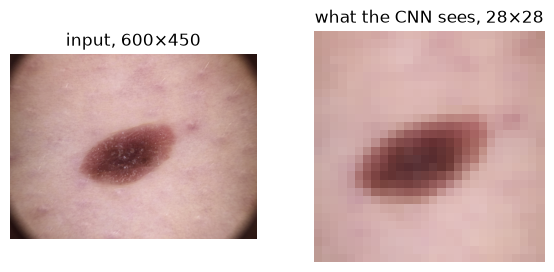

In [2]:
samples = pd.read_csv("demo/samples.csv")
images = {r.image_id: np.array(Image.open(f"demo/images/{r.image_id}.jpg").convert("RGB")) for r in samples.itertuples()}
resize, _, to_tensor = transforms_for(28)
crop = to_tensor.transforms[0]  # CenterCrop(28)

first = "ISIC_0029231"  # no ruler or other border marks that the crop would hide
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(images[first]); axes[0].set_title("input, 600×450")
axes[1].imshow(crop(resize(Image.fromarray(images[first])))); axes[1].set_title("what the CNN sees, 28×28")
for ax in axes: ax.axis("off")

## 1. Live: classify test images

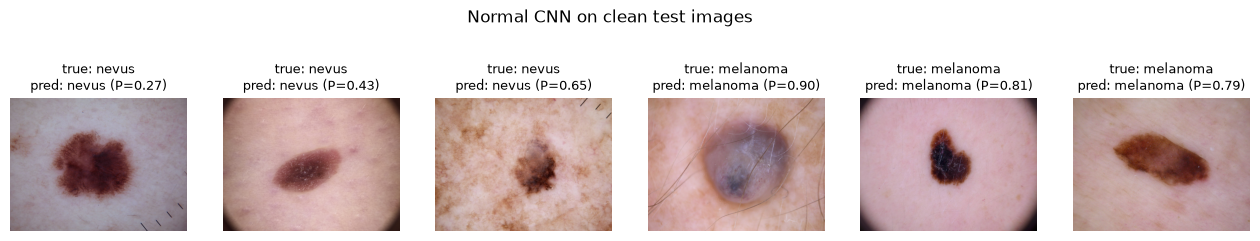

In [3]:
results = json.load(open("results/cnn/28/ink_shortcut/results.json"))["runs"]
models = {
    # name: (model, decision threshold chosen on validation)
    "normal CNN": (load_model(28, "demo/weights/cnn28.pt"),
                   json.load(open("results/cnn/28/trained.json"))["chosen"]["threshold"]),
    "ink-trained CNN (90/10)": (load_model(28, "demo/weights/cnn28_ink90-10.pt"),
                                next(r for r in results if r["level"] == "90/10" and r["seed"] == 0)["chosen"]["threshold"]),
}

@torch.no_grad()
def p_melanoma(model, rgb):
    return model(to_tensor(resize(Image.fromarray(rgb)))[None]).softmax(1)[0, 1].item()

def show(pictures, title):
    fig, axes = plt.subplots(1, len(samples), figsize=(16, 3.2))
    for ax, row in zip(axes, samples.itertuples()):
        ax.imshow(pictures[row.image_id]); ax.axis("off")
        model, threshold = models["normal CNN"]
        p = p_melanoma(model, pictures[row.image_id])
        ax.set_title(f"true: {CLASSES[row.label]}\npred: {CLASSES[p >= threshold]} (P={p:.2f})", fontsize=9)
    fig.suptitle(title)

show(images, "Normal CNN on clean test images")

## 2. Live: add synthetic ink and classify again

Each image gets one ink stroke (`src/artifacts.py`) at a precomputed spot at least 15 px away from
the lesion, so the lesion itself is unchanged.

,true,normal CNN: clean,normal CNN: ink,ink-trained CNN (90/10): clean,ink-trained CNN (90/10): ink
image,,,,,
ISIC_0029470,nevus,nevus (0.27),nevus (0.29),nevus (0.08),melanoma (0.85)
ISIC_0029231,nevus,nevus (0.43),nevus (0.43),nevus (0.65),melanoma (0.90)
ISIC_0028571,nevus,nevus (0.65),nevus (0.65),nevus (0.56),melanoma (0.85)
ISIC_0033405,melanoma,melanoma (0.90),melanoma (0.90),nevus (0.66),melanoma (0.94)
ISIC_0030440,melanoma,melanoma (0.81),melanoma (0.82),nevus (0.52),melanoma (0.86)
ISIC_0033985,melanoma,melanoma (0.79),melanoma (0.80),nevus (0.61),melanoma (0.90)


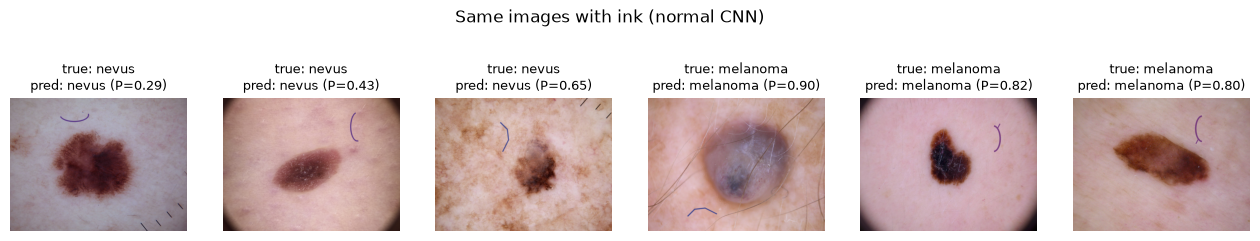

In [4]:
inked = {}
for r in samples.itertuples():
    stamp = paired_overlays("ink", r.design, r.rotation)[0]
    inked[r.image_id] = composite(images[r.image_id], stamp, r.x, r.y)

show(inked, "Same images with ink (normal CNN)")

rows = []
for r in samples.itertuples():
    row = {"image": r.image_id, "true": CLASSES[r.label]}
    for name, (model, threshold) in models.items():
        clean, ink = p_melanoma(model, images[r.image_id]), p_melanoma(model, inked[r.image_id])
        row[f"{name}: clean"] = f"{CLASSES[clean >= threshold]} ({clean:.2f})"
        row[f"{name}: ink"] = f"{CLASSES[ink >= threshold]} ({ink:.2f})"
    rows.append(row)
pd.DataFrame(rows).set_index("image")

**The normal CNN ignores the ink. The ink-trained CNN calls every inked image melanoma**, including
the three nevi, even though the lesion pixels did not change. Without ink it also misses all three
melanomas: it learned "ink ⇒ melanoma" as a shortcut instead of relying on the lesion.

These 6 images were chosen to show the effect clearly (`demo/samples.csv`). The full test set
(959 images, 3 seeds per level, `results/cnn/28/ink_shortcut/`) shows the same:

In [5]:
summary = pd.read_csv("results/cnn/28/ink_shortcut/summary.csv")
levels = ["50/50", "70/30", "90/10", "100/0"]
table = (summary[summary.model.isin(levels)]
         .groupby(["model", "condition"])[["macro_f1", "sensitivity"]].mean().unstack())
table = table.loc[levels, [("macro_f1", "biased"), ("macro_f1", "clean"), ("sensitivity", "clean")]]
table.columns = ["macro-F1, test ink like training", "macro-F1, no ink", "melanoma recall, no ink"]
baseline = summary[(summary.model == "baseline") & (summary.condition == "clean")].iloc[0]
table.loc["no ink in training"] = [np.nan, baseline.macro_f1, baseline.sensitivity]
table.index.name = "melanoma/nevus share inked in training"
table.round(3)

,"macro-F1, test ink like training","macro-F1, no ink","melanoma recall, no ink"
melanoma/nevus share inked in training,,,
50/50,0.760,0.759,0.711
70/30,0.751,0.752,0.680
90/10,0.814,0.696,0.367
100/0,0.968,0.542,0.090
no ink in training,NaN,0.763,0.659


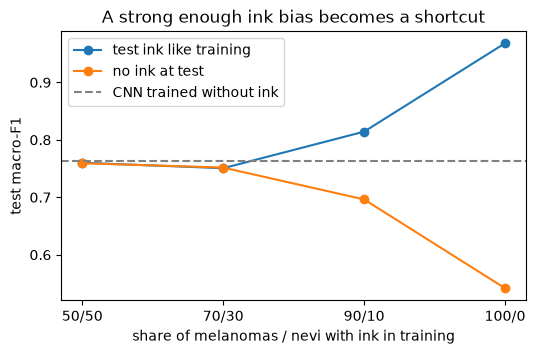

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(levels, table.iloc[:4, 0], "o-", label="test ink like training")
ax.plot(levels, table.iloc[:4, 1], "o-", label="no ink at test")
ax.axhline(baseline.macro_f1, color="gray", ls="--", label="CNN trained without ink")
ax.set_xlabel("share of melanomas / nevi with ink in training"); ax.set_ylabel("test macro-F1")
ax.set_title("A strong enough ink bias becomes a shortcut"); ax.legend()
plt.show()

## 3. Cached results (not run live)

PanDerm (ViT-L, 300M parameters) and SmolVLM (500M) need large downloads and, for SmolVLM, a GPU.
The cells below **only load saved predictions from `results/`**; the code that produced them is in
`src/`.

### Baselines on the clean test split

In [7]:
def scores(path, score="prob_mel", pred="pred"):
    p = pd.read_csv(path)
    tn, fp, fn, tp = pd.crosstab(p.label, p[pred]).to_numpy().ravel()
    return {"macro-F1": f1_score(p.label, p[pred], average="macro"), "AUROC": roc_auc_score(p.label, p[score]),
            "melanoma recall": tp / (tp + fn), "nevus specificity": tn / (tn + fp), "test images": len(p)}

baselines = pd.DataFrame({
    "CNN 28px": scores("results/cnn/28/trained_test_predictions.csv"),
    "CNN 224px": scores("results/cnn/224/trained_test_predictions.csv"),
    "Linear probe on CNN 28px embedding": scores("results/cnn/28/probe_test_predictions.csv"),
    "Linear probe on CNN 224px embedding": scores("results/cnn/224/probe_test_predictions.csv"),
    "Linear probe on PanDerm (pretrained)": scores("results/panderm/pretrained/probe_test_predictions.csv"),
    "Linear probe on PanDerm (random init)": scores("results/panderm/random_init/probe_test_predictions.csv"),
    "SmolVLM + LoRA*": scores("results/smolvlm_lora/test_predictions.csv", "conditional_melanoma_score", "prediction"),
}).T
baselines["test images"] = baselines["test images"].astype(int)
baselines.round(3)

,macro-F1,AUROC,melanoma recall,nevus specificity,test images
CNN 28px,0.764,0.888,0.690,0.901,1173
CNN 224px,0.764,0.913,0.667,0.908,1173
Linear probe on CNN 28px embedding,0.756,0.894,0.619,0.917,1173
Linear probe on CNN 224px embedding,0.733,0.890,0.589,0.906,1173
Linear probe on PanDerm (pretrained),0.855,0.953,0.792,0.948,1173
Linear probe on PanDerm (random init),0.747,0.890,0.631,0.904,1173
SmolVLM + LoRA*,0.691,0.874,0.837,0.776,1189


\*SmolVLM was trained and tested on a different lesion-grouped split (`results/smolvlm_lora/split.csv`)
with a fixed 0.5 threshold, so compare it loosely. The other models share `splits/ham10000_nv_vs_mel.csv`.

Pretrained PanDerm features are clearly the best; the same architecture with random weights falls
to CNN level, so the gain comes from pretraining.

### PanDerm: the same planted ink

The ink experiment from section 2, repeated with a linear probe on frozen PanDerm features: the same
6,421 images, ink stamps, ink levels, and test conditions (`src/panderm_ink_shortcut.py`, one seed).
The encoder never trains, so the probe can only use the ink if PanDerm's features already encode it.

PanDerm sees the image at 224×224, where the ink is much larger than in the CNN's 28×28 input:

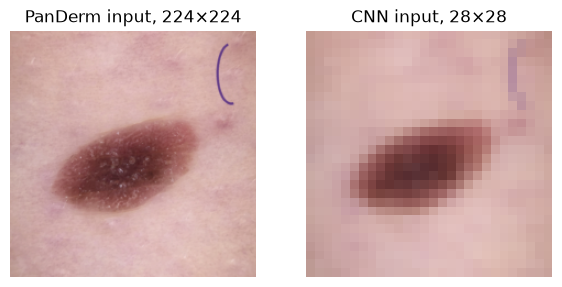

In [8]:
from panderm import TRANSFORM
panderm_crop = transforms.Compose(TRANSFORM.transforms[:2])  # Resize(256), CenterCrop(224)
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
axes[0].imshow(panderm_crop(Image.fromarray(inked[first]))); axes[0].set_title("PanDerm input, 224×224")
axes[1].imshow(crop(resize(Image.fromarray(inked[first])))); axes[1].set_title("CNN input, 28×28")
for ax in axes: ax.axis("off")

In [9]:
panderm = pd.read_csv("results/panderm/pretrained/ink_shortcut/summary.csv")

def ink_table(s):
    t = s.pivot_table(index="model", columns="condition", values=["macro_f1", "sensitivity", "auroc"])
    t = t[[("macro_f1", "biased"), ("macro_f1", "clean"), ("macro_f1", "all"), ("macro_f1", "flipped"),
           ("sensitivity", "clean"), ("auroc", "clean")]].loc[["baseline", *levels]]
    t.columns = ["macro-F1, ink like training", "macro-F1, no ink", "macro-F1, ink on all", "macro-F1, flipped",
                 "melanoma recall, no ink", "AUROC, no ink"]
    t.index.name = "melanoma/nevus share inked in training"
    return t.rename(index={"baseline": "no ink in training"})

ink_table(panderm).round(3)

,"macro-F1, ink like training","macro-F1, no ink","macro-F1, ink on all","macro-F1, flipped","melanoma recall, no ink","AUROC, no ink"
melanoma/nevus share inked in training,,,,,,
no ink in training,NaN,0.810,0.713,NaN,0.651,0.941
50/50,0.817,0.812,0.816,0.817,0.752,0.949
70/30,0.838,0.756,0.817,0.763,0.426,0.943
90/10,0.896,0.677,0.727,0.561,0.264,0.921
100/0,0.989,0.478,0.136,0.018,0.016,0.703


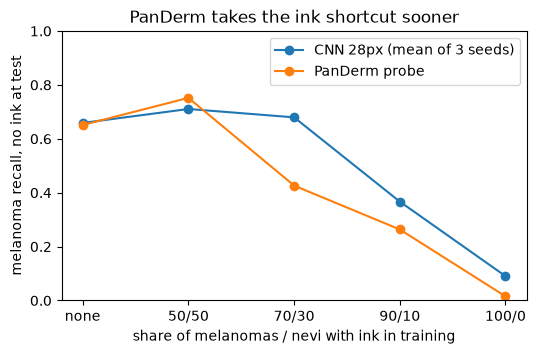

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for name, s in [("CNN 28px (mean of 3 seeds)", summary), ("PanDerm probe", panderm)]:
    ax.plot(["none", *levels], ink_table(s)["melanoma recall, no ink"], "o-", label=name)
ax.set_xlabel("share of melanomas / nevi with ink in training"); ax.set_ylabel("melanoma recall, no ink at test")
ax.set_ylim(0, 1); ax.set_title("PanDerm takes the ink shortcut sooner"); ax.legend()
plt.show()

How far adding ink to every test image moves each model's melanoma-minus-nevus logit margin
(positive = more melanoma-like):

In [11]:
def margin_shift(path):
    runs = json.load(open(path))["runs"]
    shifts = pd.DataFrame([{"level": r["model"], "melanomas": r["effects"]["mel"]["all_minus_clean_margin"],
                            "nevi": r["effects"]["nv"]["all_minus_clean_margin"]} for r in runs])
    return shifts.groupby("level").mean().loc[["baseline", *levels]].rename(index={"baseline": "no ink in training"})

pd.concat({"CNN 28px": margin_shift("results/cnn/28/ink_shortcut/results.json"),
           "PanDerm probe": margin_shift("results/panderm/pretrained/ink_shortcut/results.json")}, axis=1).round(2)

CNN 28px       PanDerm probe       
                   melanomas  nevi     melanomas   nevi
level                                                  
no ink in training      0.02  0.06         -1.54  -1.52
50/50                   0.02  0.08         -0.30  -0.21
70/30                   0.03  0.11          1.28   1.15
90/10                   1.39  1.68          4.06   3.40
100/0                   6.99  8.12         13.20  15.19

- **PanDerm takes the shortcut sooner and harder.** Its clean melanoma recall already falls at 70/30
  (0.75 → 0.43), where the CNN is unaffected, and at 90/10 ink moves its margin 2–3× more than the CNN's.
- **Ink pushes even the probe trained without ink toward nevus** (margin −1.5): ink alone halves its
  melanoma recall. The CNN trained without ink ignores it. SmolVLM shows the same push toward nevus below.
- **Up to 90/10 the probe still ranks lesions well** (no-ink AUROC ≥ 0.92); what breaks is the
  decision threshold, as with the CNN.

The no-ink probe scores 0.810 macro-F1 here vs. 0.855 in the baselines table, because this cohort excludes
the test melanomas with no room for ink (mostly large lesions).

### SmolVLM: inserting synthetic ink and rulers

The frozen SmolVLM classifier scored 914 test images with the same ink (and ruler) graphics pasted
outside the lesion, plus a control with the same pixels shuffled (`results/smolvlm_artifact_insertion/`).

,sensitivity,specificity
condition,,
original,0.833,0.790
ruler inserted,0.476,0.808
ruler control,0.254,0.920
ink inserted,0.294,0.946
ink control,0.738,0.767


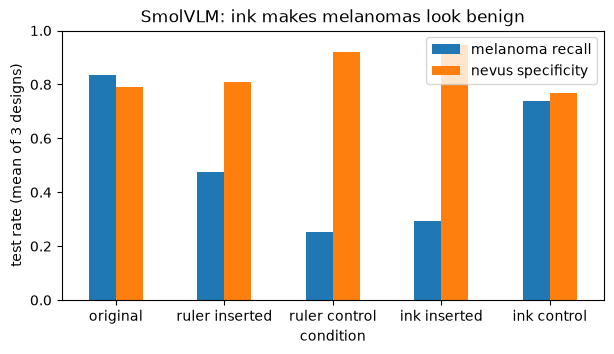

In [12]:
insertion = pd.read_csv("results/smolvlm_artifact_insertion/comparison.csv")
insertion["condition"] = np.where(insertion.artifact == "original", "original",
                                  insertion.artifact + " " + insertion.condition.str.replace("target", "inserted"))
recall = insertion.groupby("condition", sort=False)[["sensitivity", "specificity"]].mean()

fig, ax = plt.subplots(figsize=(7, 3.5))
recall.plot.bar(ax=ax, rot=0)
ax.set_ylabel("test rate (mean of 3 designs)"); ax.set_ylim(0, 1)
ax.legend(["melanoma recall", "nevus specificity"]); ax.set_title("SmolVLM: ink makes melanomas look benign")
recall.round(3)

Ink pushes SmolVLM toward "nevus": melanoma recall drops from 0.83 to 0.29, while the same ink
pixels shuffled only drop it to 0.74. This is the opposite direction from our planted CNN shortcut. In SmolVLM's
training data, ink appears only on nevi (7 images). Rulers also hurt, but so does their shuffled
control, so part of that effect is generic image damage.

More SmolVLM studies (artifact probes on its features, removing real artifacts) are summarized in
`results/smolvlm_artifact_probes/` and `results/smolvlm_mask_ablation/`.